# compare linear and cosine learning-rate decay

In [1]:
import json
import random
from datetime import datetime, timezone
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import torch
from sklearn.model_selection import train_test_split
from torch.utils.data import DataLoader, Subset

from datasets.imagenette import download_imagenette_dataset
from models.vision_transformer import build_distilled_vision_transformer, build_vision_transformer, build_vision_transformer_single_classifier
from pipeline.evaluate import evaluate_model
from pipeline.train import train_model

SEED = 0
SPLIT_SEED = 0
EPOCHS = 100
WARMUP_EPOCHS = 5
BATCH_SIZE = 32
PEAK_LR = 5e-4
WEIGHT_DECAY = 0.01
DATA_ROOT = Path("data")
RESULTS_DIR = Path("artifacts") / datetime.now(timezone.utc).strftime("%Y%m%d_%H%M%S_UTC") / "part2_schedule"
MODEL_CONFIG = dict(image_size=224, patch_size=16, hidden_dim=192, num_heads=4,
                    num_layers=6, mlp_ratio=4, num_classes=10, dropout=0.1)
device = torch.device("cuda" if torch.cuda.is_available() else
                      "mps" if torch.backends.mps.is_available() else "cpu")

def reset_seed(seed):
    random.seed(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)
    if torch.cuda.is_available():
        torch.cuda.manual_seed_all(seed)

def save_json(path, payload):
    path.parent.mkdir(parents=True, exist_ok=True)
    path.write_text(json.dumps(payload, indent=2, default=lambda value: value.tolist()) + "\n")

print(f"Device: {device}; results: {RESULTS_DIR}")

Device: mps; results: artifacts/20261111_172935_UTC/part2_schedule


## Keep the data fixed

Use only Imagenette's official **training** split, with deterministic shorter-side resize, center crop to 224, and pixel values in [0,1]. Reserve a stratified 20% of this pool for internal validation. The official validation split remains outside this notebook.

Save both the split indices and the dataset's ordered image list. The split seed and memberships remain fixed across A0 and A1. These shared deterministic transforms are intentional; augmentation belongs to a later experiment.

In [2]:
pool = download_imagenette_dataset(root_dir=str(DATA_ROOT), split="train", image_size=224)
labels = np.array([label for _, label in pool._samples])
train_indices, validation_indices = train_test_split(
    np.arange(len(pool)), test_size=0.2, stratify=labels, random_state=SPLIT_SEED,
)
train_data = Subset(pool, train_indices.tolist())
validation_data = Subset(pool, validation_indices.tolist())
validation_loader = DataLoader(validation_data, batch_size=BATCH_SIZE, shuffle=False, num_workers=0)
RESULTS_DIR.mkdir(parents=True, exist_ok=True)
np.savez(RESULTS_DIR / "split_indices.npz", train=train_indices, validation=validation_indices)
save_json(RESULTS_DIR / "dataset_manifest.json", {
    "dataset": "Imagenette", "distribution": "320px", "official_split": "train",
    "split_seed": SPLIT_SEED, "class_to_idx": pool.class_to_idx,
    "ordered_samples": [
        {"image": str(Path(path).relative_to(Path(pool._image_root))), "label": int(label)}
        for path, label in pool._samples
    ],
})
print(f"Training: {len(train_data)}; internal validation: {len(validation_data)}")

Training: 7575; internal validation: 1894


In [ ]:
def run_experiment(
    run_id,
    model_builder,
    *,
    scheduler,
    train_dataset,
    batch_transform=None,
):
    reset_seed(SEED)
    train_loader = DataLoader(
        train_dataset, batch_size=BATCH_SIZE, shuffle=True, num_workers=0,
        generator=torch.Generator().manual_seed(SEED), drop_last=False, 
    )
    warmup_steps = WARMUP_EPOCHS * len(train_loader)
    model = model_builder(**MODEL_CONFIG)
    run_dir = RESULTS_DIR / run_id
    checkpoint = run_dir / "best.pth"
    config = dict(run_id=run_id, model=MODEL_CONFIG, student_seed=SEED, split_seed=SPLIT_SEED,
                    epochs=EPOCHS, batch_size=BATCH_SIZE, learning_rate=PEAK_LR,
                    weight_decay=WEIGHT_DECAY, scheduler=scheduler,
                    warmup_steps=warmup_steps, warmup_lr=1e-6, min_lr=1e-5,
                    early_stopping_patience=None, supervision="both heads: ground-truth CE, equal weights",
                    evaluation="mean softmax probabilities", checkpoint_rule="highest validation accuracy",
                    device=str(device), torch_version=torch.__version__,
                    split_indices="../split_indices.npz", dataset_manifest="../dataset_manifest.json")
    save_json(run_dir / "config.json", config)
    history = train_model(
        model, train_loader, validation_loader, num_epochs=EPOCHS, learning_rate=PEAK_LR,
        weight_decay=WEIGHT_DECAY, device=device, checkpoint_path=checkpoint,
        scheduler=scheduler, warmup_steps=warmup_steps, warmup_lr=1e-6, min_lr=1e-5,
        early_stopping_patience=None, augment = batch_transform,
    )
    metrics = evaluate_model(model, validation_loader, device, checkpoint_path=checkpoint)
    summary = dict(run_id=run_id, parameters=sum(p.numel() for p in model.parameters()),
                    epochs_run=len(history["train_loss"]), best_epoch=history["best_epoch"],
                    validation=metrics, training_seconds=sum(history["train_seconds"]),
                    checkpoint=str(checkpoint))
    save_json(run_dir / "history.json", history)
    save_json(run_dir / "summary.json", summary)
    histories[run_id], summaries[run_id] = history, summary
    model.cpu()
    print(f"{run_id}: validation accuracy={metrics['accuracy']:.4f}, "
            f"NLL={metrics['loss']:.4f}, macro F1={metrics['macro_f1_score']:.4f}")
    return history, summary

## Shared training procedure

Each call below starts a fresh model with the same initialization seed and a fresh training-loader generator. Resetting all random generators also matches dropout and data order across the two conditions as closely as the backend permits. Seeds do not guarantee bitwise reproducibility on every device.

Both conditions receive exactly 100 epochs, the same batch handling (including the final partial batch), five epochs of warmup, AdamW, peak LR 0.0005, weight decay 0.01, and dropout 0.1. The only changed setting is the decay shape. Both schedulers explicitly start warmup at `1e-6` and decay toward `1e-5`. The peak `5e-4` is the actual optimizer rate with no batch-size scaling; these values and the 100-epoch budget are local choices, not the complete published DeiT recipe.

The pipeline minimizes the equally weighted cross-entropy losses of the two heads. Keep its existing **highest validation accuracy** checkpoint rule for both runs. Full training continues after the best epoch because early stopping is disabled. Validation NLL uses the combined probability prediction; the training loss is a different objective, so do not interpret their difference as a pure generalization gap.

# single layer classifier

In [ ]:
histories, summaries = {}, {}

def run_schedule_experiment_single_classifier(run_id, schedule_name):
    reset_seed(SEED)
    train_loader = DataLoader(
        train_data, batch_size=BATCH_SIZE, shuffle=True, num_workers=0,
        generator=torch.Generator().manual_seed(SEED), drop_last=False,
    )
    warmup_steps = WARMUP_EPOCHS * len(train_loader)
    model = build_vision_transformer_single_classifier(**MODEL_CONFIG)
    run_dir = RESULTS_DIR / run_id
    checkpoint = run_dir / "best.pth"
    config = dict(run_id=run_id, model=MODEL_CONFIG, student_seed=SEED, split_seed=SPLIT_SEED,
                  epochs=EPOCHS, batch_size=BATCH_SIZE, learning_rate=PEAK_LR,
                  weight_decay=WEIGHT_DECAY, scheduler=schedule_name,
                  warmup_steps=warmup_steps, warmup_lr=1e-6, min_lr=1e-5,
                  early_stopping_patience=None, supervision="both heads: ground-truth CE, equal weights",
                  evaluation="mean softmax probabilities", checkpoint_rule="highest validation accuracy",
                  device=str(device), torch_version=torch.__version__,
                  split_indices="../split_indices.npz", dataset_manifest="../dataset_manifest.json")
    save_json(run_dir / "config.json", config)
    history = train_model(
        model, train_loader, validation_loader, num_epochs=EPOCHS, learning_rate=PEAK_LR,
        weight_decay=WEIGHT_DECAY, device=device, checkpoint_path=checkpoint,
        scheduler=schedule_name, warmup_steps=warmup_steps, warmup_lr=1e-6, min_lr=1e-5,
        early_stopping_patience=None,
    )
    metrics = evaluate_model(model, validation_loader, device, checkpoint_path=checkpoint)
    summary = dict(run_id=run_id, parameters=sum(p.numel() for p in model.parameters()),
                   epochs_run=len(history["train_loss"]), best_epoch=history["best_epoch"],
                   validation=metrics, training_seconds=sum(history["train_seconds"]),
                   checkpoint=str(checkpoint))
    save_json(run_dir / "history.json", history)
    save_json(run_dir / "summary.json", summary)
    histories[run_id], summaries[run_id] = history, summary
    model.cpu()
    print(f"{run_id}: validation accuracy={metrics['accuracy']:.4f}, "
          f"NLL={metrics['loss']:.4f}, macro F1={metrics['macro_f1_score']:.4f}")
    return history, summary

In [ ]:
a0_history, a0_summary = run_schedule_experiment_single_classifier("A0_linear", "linear")

Epoch 1/100: train loss=2.2185, val loss=2.0725, val accuracy=0.2445, lr_start=1e-06, train=19.73s, val=3.17s
Epoch 2/100: train loss=1.9437, val loss=1.7777, val accuracy=0.3833, lr_start=0.0001, train=19.45s, val=3.21s
Epoch 3/100: train loss=1.7268, val loss=1.6674, val accuracy=0.4388, lr_start=0.0002, train=19.31s, val=3.34s
Epoch 4/100: train loss=1.5832, val loss=1.5207, val accuracy=0.4979, lr_start=0.0003, train=19.81s, val=3.36s
Epoch 5/100: train loss=1.5082, val loss=1.4916, val accuracy=0.4937, lr_start=0.0004, train=19.91s, val=3.33s
Epoch 6/100: train loss=1.3940, val loss=1.5515, val accuracy=0.4683, lr_start=0.0005, train=19.69s, val=3.24s
Epoch 7/100: train loss=1.3207, val loss=1.4050, val accuracy=0.5306, lr_start=0.00049, train=19.54s, val=3.17s
Epoch 8/100: train loss=1.2322, val loss=1.3674, val accuracy=0.5391, lr_start=0.00049, train=19.34s, val=2.68s
Epoch 9/100: train loss=1.1427, val loss=1.3593, val accuracy=0.5565, lr_start=0.00048, train=17.47s, val=2.67s

In [5]:
a1_history, a1_summary = run_schedule_experiment_single_classifier("A1_cosine", "cosine_decay")

Epoch 1/100: train loss=2.2185, val loss=2.0725, val accuracy=0.2445, lr_start=1e-06, train=19.37s, val=3.15s
Epoch 2/100: train loss=1.9437, val loss=1.7777, val accuracy=0.3833, lr_start=0.0001, train=18.67s, val=3.30s
Epoch 3/100: train loss=1.7268, val loss=1.6674, val accuracy=0.4388, lr_start=0.0002, train=19.57s, val=3.30s
Epoch 4/100: train loss=1.5832, val loss=1.5207, val accuracy=0.4979, lr_start=0.0003, train=19.23s, val=2.76s
Epoch 5/100: train loss=1.5082, val loss=1.4916, val accuracy=0.4937, lr_start=0.0004, train=19.02s, val=3.23s
Epoch 6/100: train loss=1.3950, val loss=1.5542, val accuracy=0.4694, lr_start=0.0005, train=19.20s, val=2.60s
Epoch 7/100: train loss=1.3264, val loss=1.4273, val accuracy=0.5232, lr_start=0.0005, train=17.37s, val=3.14s
Epoch 8/100: train loss=1.2482, val loss=1.3393, val accuracy=0.5576, lr_start=0.0005, train=19.20s, val=3.08s
Epoch 9/100: train loss=1.1483, val loss=1.3186, val accuracy=0.5665, lr_start=0.0005, train=19.14s, val=3.12s
Ep

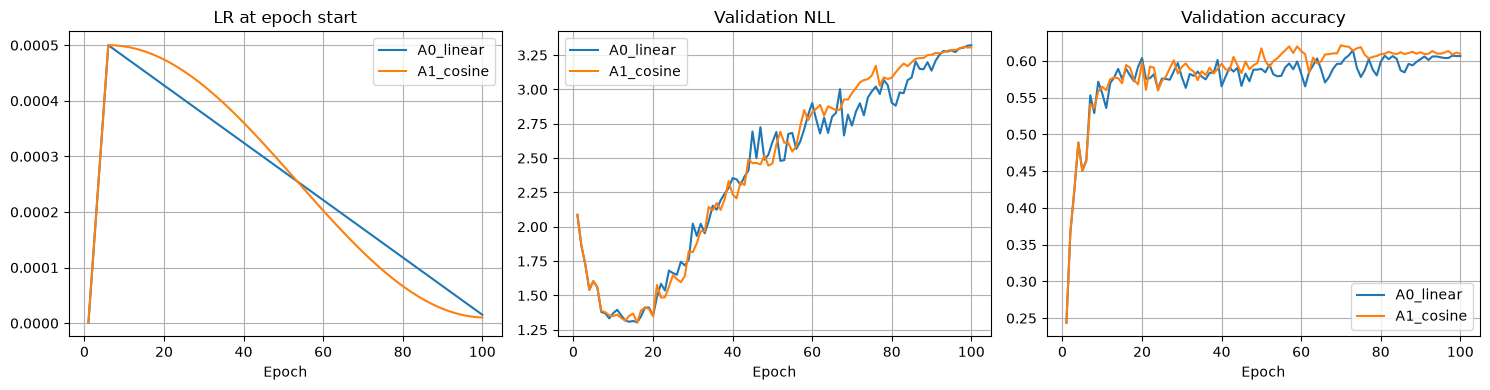

A0_linear selected epoch: 73 validation: {'accuracy': 0.614572333685322, 'f1_score': 0.6125711323890807, 'macro_f1_score': 0.6100573686902181, 'precision': 0.6176380138162197, 'recall': 0.614572333685322, 'confusion_matrix': array([[150,   6,   1,  15,   2,   5,   2,   1,   6,   5],
       [  3, 122,   5,   8,   4,  24,   6,   4,  12,   3],
       [  7,  10, 120,  10,  11,  14,  11,   5,   9,   2],
       [ 10,  17,   9,  67,  13,  19,   7,   8,  14,   8],
       [  4,   1,   7,   4, 131,  12,  10,   8,   6,   5],
       [  2,   9,   2,  19,  22, 126,   2,   4,   3,   2],
       [  7,   1,  16,   6,  14,  14, 125,   6,   1,   2],
       [  1,   8,  20,  16,  18,   8,  17,  85,   7,   6],
       [  8,  14,  14,   6,  13,  10,   5,   4,  99,  17],
       [  4,   7,   0,   7,   8,   6,   5,   5,  11, 139]]), 'loss': 2.811308026439663, 'evaluation_seconds': 3.043046167003922}
A1_cosine selected epoch: 70 validation: {'accuracy': 0.6214361140443506, 'f1_score': 0.621127910111673, 'macro_f1_

In [ ]:
if histories:
    fig, axes = plt.subplots(1, 3, figsize=(15, 4))
    for run_id, history in histories.items():
        epochs = np.arange(1, len(history["train_loss"]) + 1)
        axes[0].plot(epochs, history["learning_rate"], label=run_id)
        axes[1].plot(epochs, history["val_loss"], label=run_id)
        axes[2].plot(epochs, history["val_accuracy"], label=run_id)
    for axis, title in zip(axes, ["LR at epoch start", "Validation NLL", "Validation accuracy"]):
        axis.set(title=title, xlabel="Epoch")
        axis.grid(True)
        axis.legend()
    fig.tight_layout()
    fig.savefig(RESULTS_DIR / "schedule_comparison.png", dpi=160)
    plt.show()
    for run_id, summary in summaries.items():
        print(run_id, "selected epoch:", summary["best_epoch"], "validation:", summary["validation"])
else:
    print("No full training runs have been executed in this kernel.")

# mlp head classifier

In [6]:
histories, summaries = {}, {}

def run_schedule_experiment(run_id, schedule_name):
    reset_seed(SEED)
    train_loader = DataLoader(
        train_data, batch_size=BATCH_SIZE, shuffle=True, num_workers=0,
        generator=torch.Generator().manual_seed(SEED), drop_last=False,
    )
    warmup_steps = WARMUP_EPOCHS * len(train_loader)
    model = build_vision_transformer(**MODEL_CONFIG)
    run_dir = RESULTS_DIR / run_id
    checkpoint = run_dir / "best.pth"
    config = dict(run_id=run_id, model=MODEL_CONFIG, student_seed=SEED, split_seed=SPLIT_SEED,
                  epochs=EPOCHS, batch_size=BATCH_SIZE, learning_rate=PEAK_LR,
                  weight_decay=WEIGHT_DECAY, scheduler=schedule_name,
                  warmup_steps=warmup_steps, warmup_lr=1e-6, min_lr=1e-5,
                  early_stopping_patience=None, supervision="both heads: ground-truth CE, equal weights",
                  evaluation="mean softmax probabilities", checkpoint_rule="highest validation accuracy",
                  device=str(device), torch_version=torch.__version__,
                  split_indices="../split_indices.npz", dataset_manifest="../dataset_manifest.json")
    save_json(run_dir / "config.json", config)
    history = train_model(
        model, train_loader, validation_loader, num_epochs=EPOCHS, learning_rate=PEAK_LR,
        weight_decay=WEIGHT_DECAY, device=device, checkpoint_path=checkpoint,
        scheduler=schedule_name, warmup_steps=warmup_steps, warmup_lr=1e-6, min_lr=1e-5,
        early_stopping_patience=None,
    )
    metrics = evaluate_model(model, validation_loader, device, checkpoint_path=checkpoint)
    summary = dict(run_id=run_id, parameters=sum(p.numel() for p in model.parameters()),
                   epochs_run=len(history["train_loss"]), best_epoch=history["best_epoch"],
                   validation=metrics, training_seconds=sum(history["train_seconds"]),
                   checkpoint=str(checkpoint))
    save_json(run_dir / "history.json", history)
    save_json(run_dir / "summary.json", summary)
    histories[run_id], summaries[run_id] = history, summary
    model.cpu()
    print(f"{run_id}: validation accuracy={metrics['accuracy']:.4f}, "
          f"NLL={metrics['loss']:.4f}, macro F1={metrics['macro_f1_score']:.4f}")
    return history, summary

## A0 — linear decay

Run this first. It establishes the new two-head, teacher-free reference; it does not reuse trained Part 1 weights.

In [ ]:
a0_history, a0_summary = run_schedule_experiment("A0_linear", "linear")

Epoch 1/100: train loss=2.1786, val loss=2.1102, val accuracy=0.2254, lr_start=1e-06, train=18.58s, val=3.29s
Epoch 2/100: train loss=1.9764, val loss=1.8966, val accuracy=0.3432, lr_start=0.0001, train=18.90s, val=2.80s
Epoch 3/100: train loss=1.7824, val loss=1.6945, val accuracy=0.4319, lr_start=0.0002, train=18.76s, val=2.67s


## A1 — cosine decay

Use the same configuration and split. This call rebuilds the model and resets the training-loader generator; A1 does not continue A0's trained checkpoint.

In [ ]:
a1_history, a1_summary = run_schedule_experiment("A1_cosine", "cosine_decay")

KeyboardInterrupt: 

## Inspect the completed runs

Compare accuracy and NLL at the selected weights, the selected epochs, training time, and learning-rate curves. Differences from one seed remain exploratory. Checkpoints, configurations, histories, split membership, and summaries are saved under the displayed results directory. No test score is produced.

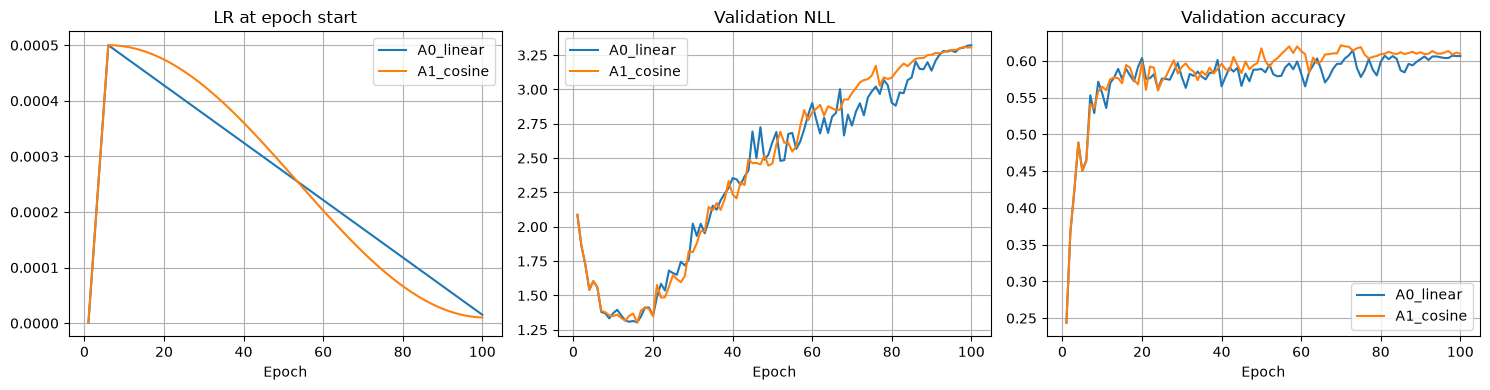

A0_linear selected epoch: 73 validation: {'accuracy': 0.614572333685322, 'f1_score': 0.6125711323890807, 'macro_f1_score': 0.6100573686902181, 'precision': 0.6176380138162197, 'recall': 0.614572333685322, 'confusion_matrix': array([[150,   6,   1,  15,   2,   5,   2,   1,   6,   5],
       [  3, 122,   5,   8,   4,  24,   6,   4,  12,   3],
       [  7,  10, 120,  10,  11,  14,  11,   5,   9,   2],
       [ 10,  17,   9,  67,  13,  19,   7,   8,  14,   8],
       [  4,   1,   7,   4, 131,  12,  10,   8,   6,   5],
       [  2,   9,   2,  19,  22, 126,   2,   4,   3,   2],
       [  7,   1,  16,   6,  14,  14, 125,   6,   1,   2],
       [  1,   8,  20,  16,  18,   8,  17,  85,   7,   6],
       [  8,  14,  14,   6,  13,  10,   5,   4,  99,  17],
       [  4,   7,   0,   7,   8,   6,   5,   5,  11, 139]]), 'loss': 2.811308026439663, 'evaluation_seconds': 3.043046167003922}
A1_cosine selected epoch: 70 validation: {'accuracy': 0.6214361140443506, 'f1_score': 0.621127910111673, 'macro_f1_

In [ ]:
if histories:
    fig, axes = plt.subplots(1, 3, figsize=(15, 4))
    for run_id, history in histories.items():
        epochs = np.arange(1, len(history["train_loss"]) + 1)
        axes[0].plot(epochs, history["learning_rate"], label=run_id)
        axes[1].plot(epochs, history["val_loss"], label=run_id)
        axes[2].plot(epochs, history["val_accuracy"], label=run_id)
    for axis, title in zip(axes, ["LR at epoch start", "Validation NLL", "Validation accuracy"]):
        axis.set(title=title, xlabel="Epoch")
        axis.grid(True)
        axis.legend()
    fig.tight_layout()
    fig.savefig(RESULTS_DIR / "schedule_comparison.png", dpi=160)
    plt.show()
    for run_id, summary in summaries.items():
        print(run_id, "selected epoch:", summary["best_epoch"], "validation:", summary["validation"])
else:
    print("No full training runs have been executed in this kernel.")

# A2 - augmentation

In [ ]:
from torchvision.transforms import RandomResizedCrop, RandomHorizontalFlip, RandAugment, RandomErasing
from torchvision.transforms.v2 import CutMix, MixUp
import torchvision.transforms as T
from torchvision.transforms import InterpolationMode

IMAGE_SIZE = 224

transform = T.Compose(
    T.ToTensor(),
    RandomResizedCrop(IMAGE_SIZE, interpolation=InterpolationMode.BICUBIC),
    RandomHorizontalFlip(0.5),
    RandAugment(num_ops=2, magnitude= 9, interpolation=InterpolationMode.BILINEAR),
    RandomErasing(0.25),
    MixUp(num_classes=MODEL_CONFIG["num_classes"], alpha=0.8),
    CutMix(num_classes=MODEL_CONFIG["num_classes"], alpha=1.0)
)

In [ ]:
pool = download_imagenette_dataset(root_dir=str(DATA_ROOT), split="train", image_size=224, transforms=transform)
labels = np.array([label for _, label in pool._samples])
train_indices, validation_indices = train_test_split(
    np.arange(len(pool)), test_size=0.2, stratify=labels, random_state=SPLIT_SEED,
)
train_data = Subset(pool, train_indices.tolist())
validation_data = Subset(pool, validation_indices.tolist())
validation_loader = DataLoader(validation_data, batch_size=BATCH_SIZE, shuffle=False, num_workers=0)
RESULTS_DIR.mkdir(parents=True, exist_ok=True)
np.savez(RESULTS_DIR / "split_indices.npz", train=train_indices, validation=validation_indices)
save_json(RESULTS_DIR / "dataset_manifest.json", {
    "dataset": "Imagenette", "distribution": "320px", "official_split": "train",
    "split_seed": SPLIT_SEED, "class_to_idx": pool.class_to_idx,
    "ordered_samples": [
        {"image": str(Path(path).relative_to(Path(pool._image_root))), "label": int(label)}
        for path, label in pool._samples
    ],
})
print(f"Training: {len(train_data)}; internal validation: {len(validation_data)}")

In [ ]:
histories, summaries = {}, {}

def run_schedule_experiment(run_id, schedule_name):
    reset_seed(SEED)
    train_loader = DataLoader(
        train_data, batch_size=BATCH_SIZE, shuffle=True, num_workers=0,
        generator=torch.Generator().manual_seed(SEED), drop_last=False,
    )
    warmup_steps = WARMUP_EPOCHS * len(train_loader)
    model = build_vision_transformer(**MODEL_CONFIG)
    run_dir = RESULTS_DIR / run_id
    checkpoint = run_dir / "best.pth"
    config = dict(run_id=run_id, model=MODEL_CONFIG, student_seed=SEED, split_seed=SPLIT_SEED,
                  epochs=EPOCHS, batch_size=BATCH_SIZE, learning_rate=PEAK_LR,
                  weight_decay=WEIGHT_DECAY, scheduler=schedule_name,
                  warmup_steps=warmup_steps, warmup_lr=1e-6, min_lr=1e-5,
                  early_stopping_patience=None, supervision="both heads: ground-truth CE, equal weights",
                  evaluation="mean softmax probabilities", checkpoint_rule="highest validation accuracy",
                  device=str(device), torch_version=torch.__version__,
                  split_indices="../split_indices.npz", dataset_manifest="../dataset_manifest.json")
    save_json(run_dir / "config.json", config)
    history = train_model(
        model, train_loader, validation_loader, num_epochs=EPOCHS, learning_rate=PEAK_LR,
        weight_decay=WEIGHT_DECAY, device=device, checkpoint_path=checkpoint,
        scheduler=schedule_name, warmup_steps=warmup_steps, warmup_lr=1e-6, min_lr=1e-5,
        early_stopping_patience=None,
    )
    metrics = evaluate_model(model, validation_loader, device, checkpoint_path=checkpoint)
    summary = dict(run_id=run_id, parameters=sum(p.numel() for p in model.parameters()),
                   epochs_run=len(history["train_loss"]), best_epoch=history["best_epoch"],
                   validation=metrics, training_seconds=sum(history["train_seconds"]),
                   checkpoint=str(checkpoint))
    save_json(run_dir / "history.json", history)
    save_json(run_dir / "summary.json", summary)
    histories[run_id], summaries[run_id] = history, summary
    model.cpu()
    print(f"{run_id}: validation accuracy={metrics['accuracy']:.4f}, "
          f"NLL={metrics['loss']:.4f}, macro F1={metrics['macro_f1_score']:.4f}")
    return history, summary

In [ ]:
a2_history, a2_summary = run_schedule_experiment("A2_augmentation", "data_augmentation")

In [ ]:
if histories:
    fig, axes = plt.subplots(1, 3, figsize=(15, 4))
    for run_id, history in histories.items():
        epochs = np.arange(1, len(history["train_loss"]) + 1)
        axes[0].plot(epochs, history["learning_rate"], label=run_id)
        axes[1].plot(epochs, history["val_loss"], label=run_id)
        axes[2].plot(epochs, history["val_accuracy"], label=run_id)
    for axis, title in zip(axes, ["LR at epoch start", "Validation NLL", "Validation accuracy"]):
        axis.set(title=title, xlabel="Epoch")
        axis.grid(True)
        axis.legend()
    fig.tight_layout()
    fig.savefig(RESULTS_DIR / "schedule_comparison.png", dpi=160)
    plt.show()
    for run_id, summary in summaries.items():
        print(run_id, "selected epoch:", summary["best_epoch"], "validation:", summary["validation"])
else:
    print("No full training runs have been executed in this kernel.")